# 01 — Raw audit of the metro incidents file

**Goal.** Look at the incidents file *exactly as published* and decide which columns
need cleaning before any modelling. Nothing here changes the data: every finding
becomes an item on the cleaning to-do list at the bottom, which the cleaning scripts
in `code/cleaning/` will implement.

**What we check**
1. Structure: shape, column meanings, duplicates
2. Missing values: how many, and whether they are *structural* (expected) or real gaps
3. Type mismatches: values that do not parse as the type the column should have
4. Calendar consistency between the several date columns
5. Spelling / naming variants of the same thing (lines, locations)
6. Logical consistency between related columns (cause hierarchy, recorded times vs duration bucket)
7. Coverage over time and first visual trends

Source documentation: Ville de Montréal open-data page *Incidents du réseau du métro*
(PDF copy shipped with the challenge).

## 0. Setup

In [1]:
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The notebook lives in code/exploration/; config.py lives in code/.
# Adding code/ to the import path lets us reuse the same paths as the pipeline.
sys.path.insert(0, str(Path.cwd().parent))
import config

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. Load the raw file

We read **every column as text** and switch off pandas' automatic missing-value
detection. That way we see the raw values (`#`, `#N/A`, `Non affecté`, ...) instead of
pandas silently turning some of them into `NaN` and leaving others alone.

The file is `;`-separated and starts with a UTF-8 byte-order mark, hence `utf-8-sig`.

In [2]:
raw = pd.read_csv(
    config.INCIDENTS_RAW,
    sep=";",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False,
)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

45,561 rows x 26 columns


,Numero d'incident,Type d'incident,Cause primaire,Cause secondaire,Symptome,Ligne,Numéro de tournée,Heure de l'incident,Heure de reprise,Incident en minutes,Véhicule,Porte de voiture,Type de matériel,Code de lieu,Dommage matériel,KFS,Porte,Urgence métro,CAT,Évacuation,Année civile,Année civile/mois,Mois calendrier,Jour du mois,Jour de la semaine,Jour calendaire
0,S01011901,S,Autres,Autres,Clientèle,Ligne orange,#,02:56,03:32,02 min et moins,#,#,Non affecté,Snowdon,0,0,0,0,0,#,2019,janv-19,1,1,2,2019-01-01
1,S01011902,S,Autres,Autres,Clientèle,Ligne orange,#,02:56,03:42,02 min et moins,#,#,Non affecté,Snowdon,0,0,0,0,0,#,2019,janv-19,1,1,2,2019-01-01
2,S01011903,S,Autres,Autres,Clientèle,Ligne verte,#,03:35,04:41,02 min et moins,#,#,Non affecté,Place-des-Arts,0,0,0,0,0,#,2019,janv-19,1,1,2,2019-01-01
3,S01011904,S,Autres,Autres,Clientèle,Ligne verte,#,04:56,05:36,02 min et moins,#,#,Non affecté,Lionel-Groulx,0,0,0,0,0,#,2019,janv-19,1,1,2,2019-01-01
4,S01011905,S,Autres,Autres,Clientèle,Ligne verte,#,05:25,05:54,02 min et moins,#,#,Non affecté,Berri-UQAM,0,0,0,0,0,#,2019,janv-19,1,1,2,2019-01-01


## 2. Data dictionary

English meaning of each column, taken from the official documentation, plus one
extra field that matters a lot for modelling: **when is the value known?**

* `at report` — known when the incident is first declared (usable to predict escalation)
* `after` — filled in after the incident ends or after a later investigation
  (using it to predict severity would be *leakage*)
* `calendar` — date fields, known at report time

In [3]:
dictionary = pd.DataFrame(
    [
        ("Numero d'incident",   "Incident ID (prefix T = train, S = station)",          "at report"),
        ("Type d'incident",     "Incident type: T = train, S = station",                "at report"),
        ("Cause primaire",      "Primary cause, set after investigation",               "after"),
        ("Cause secondaire",    "Secondary cause, set after investigation",             "after"),
        ("Symptome",            "Initial cause attributed at the time of the incident", "at report"),
        ("Ligne",               "Metro line (1 green, 2 orange, 4 yellow, 5 blue)",     "at report"),
        ("Numéro de tournée",   "Train run number; # = no run attached",                "at report"),
        ("Heure de l'incident", "Start of customer delay (train) / of incident (station)", "at report"),
        ("Heure de reprise",    "End of customer delay (train) / of incident (station)",   "after"),
        ("Incident en minutes", "Service-delay duration, binned",                       "after"),
        ("Véhicule",            "Car number involved; # = none",                        "at report"),
        ("Porte de voiture",    "Door number(s) involved; # = none",                    "at report"),
        ("Type de matériel",    "Rolling stock: 73 = MR-73, 10 = MPM-10",               "at report"),
        ("Code de lieu",        "Location: station, inter-station, facility",           "at report"),
        ("Dommage matériel",    "Possible damage to the train (0/1)",                   "after"),
        ("KFS",                 "Customer pulled the emergency brake (0/1)",            "at report"),
        ("Porte",               "A door is involved (0/1)",                             "at report"),
        ("Urgence métro",       "Metro emergency team called in by control (0/1)",      "after"),
        ("CAT",                 "Traction power cut (0/1)",                             "after"),
        ("Évacuation",          "Evacuation of car / train / station; # = none",        "after"),
        ("Année civile",        "Year",                                                 "calendar"),
        ("Année civile/mois",   "Month label, e.g. janv-19",                            "calendar"),
        ("Mois calendrier",     "Month number",                                         "calendar"),
        ("Jour du mois",        "Day of month",                                         "calendar"),
        ("Jour de la semaine",  "Day of week as a number",                              "calendar"),
        ("Jour calendaire",     "Calendar date (YYYY-MM-DD)",                           "calendar"),
    ],
    columns=["column", "meaning", "known_when"],
)

# Guard against the dictionary drifting away from the actual file.
assert list(dictionary["column"]) == list(raw.columns)
dictionary

,column,meaning,known_when
0,Numero d'incident,"Incident ID (prefix T = train, S = station)",at report
1,Type d'incident,"Incident type: T = train, S = station",at report
2,Cause primaire,"Primary cause, set after investigation",after
3,Cause secondaire,"Secondary cause, set after investigation",after
4,Symptome,Initial cause attributed at the time of the in...,at report
5,Ligne,"Metro line (1 green, 2 orange, 4 yellow, 5 blue)",at report
6,Numéro de tournée,Train run number; # = no run attached,at report
7,Heure de l'incident,Start of customer delay (train) / of incident ...,at report
8,Heure de reprise,End of customer delay (train) / of incident (s...,after
9,Incident en minutes,"Service-delay duration, binned",after


The `at report` / `after` split for the flags (`CAT`, `Urgence métro`, `Évacuation`,
`Dommage matériel`) is a judgement call: the documentation does not say when they are
recorded. They describe the *response* to an incident, so we treat them as `after`
until proven otherwise. We come back to this when we pick features.

## 3. Duplicates

In [4]:
id_col = "Numero d'incident"

# (a) Is the incident ID a true key?
n_dup_ids = raw[id_col].duplicated().sum()

# (b) Identical rows apart from the ID: the same event possibly logged twice.
other_cols = raw.columns.drop(id_col)
n_dup_content = raw.duplicated(subset=other_cols).sum()

print(f"Duplicated incident IDs:              {n_dup_ids}")
print(f"Rows identical except for the ID:     {n_dup_content}")

Duplicated incident IDs:              0
Rows identical except for the ID:     5


In [5]:
# Look at a few of the content duplicates to judge whether they are real double entries
# or distinct incidents that just happen to share every recorded field.
dup_mask = raw.duplicated(subset=other_cols, keep=False)
dups = raw[dup_mask].sort_values(list(other_cols))

print("Content duplicates by incident type:")
print(dups["Type d'incident"].value_counts().to_string())
dups.head(6)

Content duplicates by incident type:
Type d'incident
S    8
T    2


,Numero d'incident,Type d'incident,Cause primaire,Cause secondaire,Symptome,Ligne,Numéro de tournée,Heure de l'incident,Heure de reprise,Incident en minutes,Véhicule,Porte de voiture,Type de matériel,Code de lieu,Dommage matériel,KFS,Porte,Urgence métro,CAT,Évacuation,Année civile,Année civile/mois,Mois calendrier,Jour du mois,Jour de la semaine,Jour calendaire
16254,S31082103,S,Autres,Autres,Clientèle,Ligne bleue,#,17:59,19:08,02 min et moins,#,#,Non affecté,Outremont,0,0,0,0,0,#,2021,août-21,8,31,2,2021-08-31
16255,S31082104,S,Autres,Autres,Clientèle,Ligne bleue,#,17:59,19:08,02 min et moins,#,#,Non affecté,Outremont,0,0,0,0,0,#,2021,août-21,8,31,2,2021-08-31
3980,S07122311,S,Autres,Autres,Clientèle,Ligne bleue,#,18:58,19:52,02 min et moins,#,#,Non affecté,Jean-Talon,0,0,0,0,0,#,2023,déc-23,12,7,4,2023-12-07
3981,S07122312,S,Autres,Autres,Clientèle,Ligne bleue,#,18:58,19:52,02 min et moins,#,#,Non affecté,Jean-Talon,0,0,0,0,0,#,2023,déc-23,12,7,4,2023-12-07
242,S01042203,S,Autres,Autres,Clientèle,Ligne verte,#,16:20,16:30,02 min et moins,#,#,Non affecté,Papineau,0,0,0,0,0,#,2022,avr-22,4,1,5,2022-04-01
244,S01042205,S,Autres,Autres,Clientèle,Ligne verte,#,16:20,16:30,02 min et moins,#,#,Non affecté,Papineau,0,0,0,0,0,#,2022,avr-22,4,1,5,2022-04-01


**Finding.** The ID is a clean key. Five pairs of rows are identical in every field
except the ID, and their IDs are consecutive (e.g. `S31082103` / `S31082104`). That
pattern looks like double entry rather than two real incidents, but the volume
(10 rows out of 45,561) is too small to matter either way.

## 4. Missing values

Since everything was read as text, missing values show up as **placeholder strings**.
We count each one per column.

* `#` is documented as "not applicable / none" for some columns
* `#N/A` looks like a spreadsheet lookup failure
* `Non affecté` ("not assigned") is used as a placeholder in a few category columns
* `""` would be a truly empty cell

In [6]:
SENTINELS = ["#", "#N/A", "Non affecté", ""]

missing = pd.DataFrame({s: (raw == s).sum() for s in SENTINELS})
missing["total"] = missing.sum(axis=1)
missing["pct"] = (100 * missing["total"] / len(raw)).round(1)

# Show only the columns that have at least one placeholder value.
missing = missing[missing["total"] > 0].sort_values("total", ascending=False)
missing

,#,#N/A,Non affecté,,total,pct
Évacuation,44190,0,0,0,44190,97.0
Porte de voiture,42766,0,0,0,42766,93.9
Type de matériel,0,0,41416,0,41416,90.9
Véhicule,33964,0,0,0,33964,74.5
Numéro de tournée,21846,0,0,0,21846,47.9
Cause primaire,0,482,0,0,482,1.1
Cause secondaire,0,482,0,0,482,1.1
Symptome,0,377,0,0,377,0.8
Ligne,0,0,103,0,103,0.2


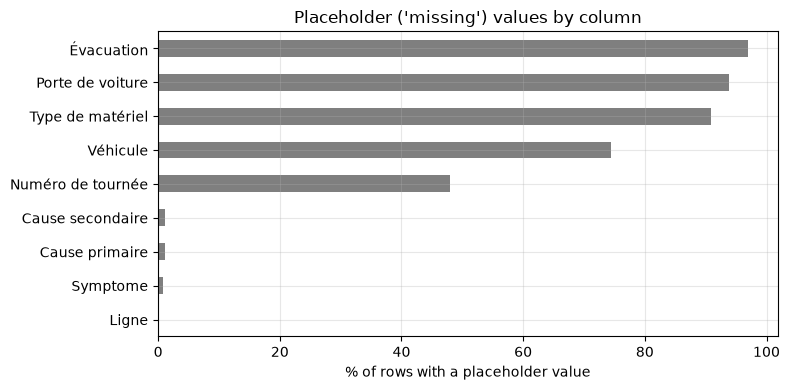

In [7]:
# Plot: share of rows holding a placeholder value, per column.
fig, ax = plt.subplots(figsize=(8, 4))
missing["pct"].sort_values().plot.barh(ax=ax, color="tab:gray")
ax.set_xlabel("% of rows with a placeholder value")
ax.set_title("Placeholder ('missing') values by column")
plt.tight_layout()
plt.show()

A high share is not automatically a problem. A station incident has no train, so
`Véhicule = #` is the *correct* value for it. The next cell splits missingness by
incident type to separate **structural** blanks from **real gaps**.

In [8]:
# Share of placeholder values, split by incident type (T = train, S = station).
type_col = "Type d'incident"
cols_with_missing = missing.index.tolist()

is_placeholder = raw[cols_with_missing].isin(SENTINELS)
by_type = (100 * is_placeholder.groupby(raw[type_col]).mean()).round(1).T
by_type.columns = [f"% missing, type {t}" for t in by_type.columns]
by_type

,"% missing, type S","% missing, type T"
Évacuation,100.0,95.3
Porte de voiture,100.0,90.4
Type de matériel,100.0,85.8
Véhicule,100.0,60.2
Numéro de tournée,100.0,18.7
Cause primaire,0.0,1.7
Cause secondaire,0.0,1.7
Symptome,1.8,0.3
Ligne,0.0,0.3


## 5. Type mismatches

For each column we state the type it *should* have and count the values that do not
fit. Placeholders are excluded here because section 4 already counted them.

In [9]:
def share_not_matching(series: pd.Series, pattern: str) -> float:
    # Percent of non-placeholder values that do not fully match a regex.
    values = series[~series.isin(SENTINELS)]
    return round(100 * (~values.str.fullmatch(pattern)).mean(), 2)


# Expected format of each column, written as a regex.
EXPECTED = {
    "Numero d'incident":   r"[TS]\d{8}",
    "Numéro de tournée":   r"\d+",
    "Heure de l'incident": r"\d{2}:\d{2}",
    "Heure de reprise":    r"\d{2}:\d{2}",
    "Véhicule":            r"\d+",
    "Porte de voiture":    r"([1-8];)+",
    "Type de matériel":    r"73|10",
    "Dommage matériel":    r"[01]",
    "KFS":                 r"[01]",
    "Porte":               r"[01]",
    "Urgence métro":       r"[01]",
    "CAT":                 r"[01]",
    "Année civile":        r"\d{4}",
    "Mois calendrier":     r"\d{1,2}",
    "Jour du mois":        r"\d{1,2}",
    "Jour de la semaine":  r"[1-7]",
    "Jour calendaire":     r"\d{4}-\d{2}-\d{2}",
}

type_check = pd.Series(
    {col: share_not_matching(raw[col], pattern) for col, pattern in EXPECTED.items()},
    name="% not matching expected format",
)
type_check.sort_values(ascending=False).to_frame()

,% not matching expected format
Heure de reprise,7.17
Heure de l'incident,5.08
Numero d'incident,0.00
Urgence métro,0.00
Jour de la semaine,0.00
Jour du mois,0.00
Mois calendrier,0.00
Année civile,0.00
CAT,0.00
KFS,0.00


The time columns are the only ones that break their expected format. Let's look at them.

In [10]:
# Time columns: which string formats appear, and how often?
time_cols = ["Heure de l'incident", "Heure de reprise"]

for col in time_cols:
    # Replace every digit with 9 so values collapse into their format, e.g. "99:99".
    formats = raw[col].str.replace(r"\d", "9", regex=True).value_counts()
    print(f"{col}:\n{formats.to_string()}\n")

# Hours greater than 23 only make sense if the clock keeps running past midnight.
hours = raw["Heure de l'incident"].str.slice(0, 2).astype(int)
print("Start-hour distribution for hours >= 24:")
print(hours[hours >= 24].value_counts().sort_index().to_string())

Heure de l'incident:
Heure de l'incident
99:99       43245
99:99:99     2316

Heure de reprise:
Heure de reprise
99:99       42293
99:99:99     3268

Start-hour distribution for hours >= 24:
Heure de l'incident
24    1460
25     856


In [11]:
# Do the long format (HH:MM:SS) and the hours >= 24 always go together?
long_format = raw["Heure de l'incident"].str.len() == 8
after_midnight = hours >= 24
pd.crosstab(long_format, after_midnight,
            rownames=["HH:MM:SS format"], colnames=["hour >= 24"])

hour >= 24,False,True
HH:MM:SS format,,
False,43245,0
True,0,2316


Times like `25:26:00` follow the transit **"service day"** convention: a service day
that starts on the 1st keeps counting hours past midnight (24:xx, 25:xx) until the
metro closes. They are not errors, but they need converting to real timestamps.
Section 6 checks which date they are attached to.

## 6. Calendar consistency

The file has five date-related columns. They should all tell the same story.

In [12]:
cal_date = pd.to_datetime(raw["Jour calendaire"], format="%Y-%m-%d")
print(f"Date range: {cal_date.min().date()} to {cal_date.max().date()}")

checks = pd.DataFrame({
    "year matches":         raw["Année civile"].astype(int) == cal_date.dt.year,
    "month matches":        raw["Mois calendrier"].astype(int) == cal_date.dt.month,
    "day-of-month matches": raw["Jour du mois"].astype(int) == cal_date.dt.day,
    # Assume the weekday number counts from 1 = Monday (pandas counts from 0 = Monday).
    "weekday matches":      raw["Jour de la semaine"].astype(int) == cal_date.dt.dayofweek + 1,
})
(100 * (1 - checks.mean())).round(2).rename("% mismatching").to_frame()

Date range: 2019-01-01 to 2025-09-30


,% mismatching
year matches,0.05
month matches,0.24
day-of-month matches,5.21
weekday matches,5.21


In [13]:
# Are the mismatches the after-midnight rows from section 5?
mismatch_any = ~checks.all(axis=1)
pd.crosstab(mismatch_any, after_midnight,
            rownames=["any calendar mismatch"], colnames=["start hour >= 24"])

start hour >= 24,False,True
any calendar mismatch,,
False,43185,0
True,60,2316


In [14]:
# Example rows past 24:00: service-day fields vs calendar date.
cols = ["Numero d'incident", "Heure de l'incident", "Année civile", "Mois calendrier",
        "Jour du mois", "Jour de la semaine", "Jour calendaire"]
raw.loc[mismatch_any & after_midnight, cols].head(5)

,Numero d'incident,Heure de l'incident,Année civile,Mois calendrier,Jour du mois,Jour de la semaine,Jour calendaire
35,S01012203,25:26:00,2022,1,1,6,2022-01-02
73,S01021918,24:43:00,2019,2,1,5,2019-02-02
99,S01022205,24:28:00,2022,2,1,2,2022-02-02
105,S01022306,24:26:00,2023,2,1,3,2023-02-02
126,S01022513,24:17:00,2025,2,1,6,2025-02-02


Reading the examples: `Année civile`, `Mois calendrier`, `Jour du mois` and
`Jour de la semaine` describe the **service day**, while `Jour calendaire` is the real
**calendar date** (one day later once the clock passes 24:00).

That accounts for most mismatches, but the table above also shows a small group that
mismatches *without* an hour >= 24. Let's look at those.

In [15]:
# Mismatching rows whose start hour is below 24.
odd = raw.loc[mismatch_any & ~after_midnight]
print(f"Rows: {len(odd)}")
print("Start times in this group:", odd["Heure de l'incident"].value_counts().to_dict())
odd[cols].head(5)

Rows: 60
Start times in this group: {'02:00': 60}


,Numero d'incident,Heure de l'incident,Année civile,Mois calendrier,Jour du mois,Jour de la semaine,Jour calendaire
9,S01012001,02:00,2020,1,1,3,2020-01-02
10,S01012002,02:00,2020,1,1,3,2020-01-02
11,S01012003,02:00,2020,1,1,3,2020-01-02
12,S01012004,02:00,2020,1,1,3,2020-01-02
13,S01012005,02:00,2020,1,1,3,2020-01-02


All of them start at exactly `02:00` and belong to the *previous* service day: on the
service-day clock they should read `26:00`. So the after-midnight convention is not
applied consistently. `02:00` may also be a default value typed in when the real time
was unknown.

The incident ID appears to encode the service date as `DDMMYY` (e.g. `S01012001` =
service day 01-01-2020, entry 01). If so, it gives an independent check on the date
fields:

In [16]:
# Decode the service date from characters 2-7 of the ID and compare with the
# service-day fields (year, month, day of month).
id_date = pd.to_datetime(raw[id_col].str.slice(1, 7), format="%d%m%y")
service_date = pd.to_datetime(dict(
    year=raw["Année civile"].astype(int),
    month=raw["Mois calendrier"].astype(int),
    day=raw["Jour du mois"].astype(int),
))
print(f"ID date == service-day fields: {100 * (id_date == service_date).mean():.2f}% of rows")

ID date == service-day fields: 100.00% of rows


**Finding.** The service date (ID = year/month/day-of-month fields) is the reliable
anchor. The cleaning step should build: service date + minutes since the start of the
service day (treating the `02:00` group as 26:00) = one real timestamp.

## 7. Naming variants — `Ligne` (metro line)

The documentation lists four lines. Anything else needs explaining.

In [17]:
raw["Ligne"].value_counts().to_frame("rows")

,rows
Ligne,
Ligne verte,20047
Ligne orange,17994
Ligne bleue,4640
Ligne jaune,2398
"Ligne 1, 2",121
Non affecté,103
"Ligne 1, 2, 4",88
"Ligne 2, 5",48
"Ligne 2, 1",43


In [18]:
# Multi-line values list the same lines in different orders ("Ligne 1, 2" vs "Ligne 2, 1").
# Sorting the line numbers shows how many distinct line *sets* there really are.
multi = raw.loc[raw["Ligne"].str.contains(","), "Ligne"]
line_set = multi.str.findall(r"\d").map(lambda nums: ", ".join(sorted(nums)))

pd.DataFrame({"raw spellings": multi.groupby(line_set).unique().map(list),
              "rows": line_set.value_counts()})

,raw spellings,rows
Ligne,,
"1, 2","[Ligne 1, 2, Ligne 2, 1]",164
"1, 2, 4","[Ligne 1, 2, 4, Ligne 2, 1, 4, Ligne 4, 2, 1, ...",101
"1, 2, 4, 5","[Ligne 1, 2, 4, 5]",28
"1, 2, 5","[Ligne 1, 2, 5, Ligne 2, 1, 5]",10
"1, 4","[Ligne 1, 4, Ligne 4, 1]",5
"1, 5","[Ligne 5, 1, Ligne 1, 5]",2
"2, 4","[Ligne 2, 4]",5
"2, 5","[Ligne 5, 2, Ligne 2, 5]",63


In [19]:
# "02-avr" is not a line. It looks like a spreadsheet turned "2, 4" into a date (2 April).
# Check the row's location and causes for clues.
raw.loc[raw["Ligne"] == "02-avr"].T

,17037
Numero d'incident,T01082509
Type d'incident,T
Cause primaire,Exploitation trains
Cause secondaire,"Ligne 1, 2, 4, 5"
Symptome,Matériel roulant
Ligne,02-avr
Numéro de tournée,41
Heure de l'incident,24:00:00
Heure de reprise,24:07:00
Incident en minutes,05 à 09 min


**Findings for `Ligne`.**
* 4 real lines, plus multi-line incidents (mostly at transfer stations such as
  Berri-UQAM, Lionel-Groulx, Jean-Talon, Snowdon) written in several orders.
* `Non affecté`: not tied to a line.
* `02-avr`: a date-converted spreadsheet value (probably "2, 4" or similar). One row,
  with no way to recover the original.

## 8. Naming variants — `Code de lieu` (location)

Free-text location with many distinct values. We check (a) spellings that differ
only by case, accents or punctuation, and (b) what *kinds* of locations are mixed in
one column.

In [20]:
def fold(text: str) -> str:
    # Lower-case, strip accents and drop every non-alphanumeric character,
    # so "Côte-Vertu" and "COTE VERTU" map to the same key.
    ascii_text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()
    return "".join(ch for ch in ascii_text.lower() if ch.isalnum())


locations = pd.Series(raw["Code de lieu"].unique())
groups = locations.groupby(locations.map(fold)).agg(list)
collisions = groups[groups.map(len) > 1]

print(f"Distinct raw locations: {len(locations)}")
print(f"Groups that collapse under case/accent/punctuation folding: {len(collisions)}")
collisions

Distinct raw locations: 230
Groups that collapse under case/accent/punctuation folding: 0


Series([], dtype: object)

In [21]:
# Sort each location into a rough kind using simple text rules.
def location_kind(loc: str) -> str:
    if loc.startswith("Ligne") or loc == "Réseau":
        return "whole line(s) / network"
    if " - Ligne" in loc:
        return "station, platform of given line(s)"
    # Segments are usually "A/B", but a few use "A - B" (e.g. "Montmorency - De La Concorde").
    if "/" in loc or " - " in loc:
        return "between two stations"
    if loc.endswith(" PR"):
        return "PR (ancillary structure)"
    if loc.isupper() or loc.split()[0] in {"Garage", "Arrière", "Centre", "Atelier"}:
        return "yard / shop / facility"
    return "station (or other)"


loc_counts = raw["Code de lieu"].value_counts()
kinds = loc_counts.groupby(loc_counts.index.map(location_kind)).agg(["count", "sum"])
kinds.columns = ["distinct values", "rows"]
kinds.sort_values("rows", ascending=False)

,distinct values,rows
Code de lieu,,
station (or other),71,41320
between two stations,71,1960
yard / shop / facility,26,1328
PR (ancillary structure),30,392
whole line(s) / network,18,309
"station, platform of given line(s)",14,252


In [22]:
# Same station, several spellings: list every location that mentions a given name.
for name in ["Berri", "Lionel-Groulx", "Montmorency", "Armes"]:
    hits = loc_counts[loc_counts.index.str.contains(name, case=False)]
    print(f"--- contains '{name}' ---\n{hits.to_string()}\n")

--- contains 'Berri' ---
Code de lieu
Berri-UQAM                    3813
Berri L-2                     1124
Berri-UQAM/Beaudry              70
Berri-UQAM - Ligne 1, 2, 4      66
Berri-UQAM/Jean-Drapeau         55
ARRIERE-GARE BERRI-UQAM         46
Champs-de-Mars/Berri-UQAM       34
Berri-UQAM/Sherbrooke           32
St-Laurent/Berri-UQAM           28
Berri-UQAM - Ligne 1, 2         17
Berri-UQAM - Ligne 2, 1          8
Berri-UQAM - Ligne 2, 1, 4       7
Berri-UQAM - Ligne 1, 4          2
Berri-UQAM - Ligne 4, 1          2
Berri-UQAM - Ligne 4, 1, 2       2
Berri-UQAM - Ligne 2, 4          2

--- contains 'Lionel-Groulx' ---
Code de lieu
Lionel-Groulx                   1400
Lionel-Groulx - Ligne 1, 2        75
Charlevoix/Lionel-Groulx          42
Lionel-Groulx/Atwater             37
Lionel-Groulx - Ligne 2, 1        30
Lionel-Groulx/Georges-Vanier      24
Place St-Henri/Lionel-Groulx      17

--- contains 'Montmorency' ---
Code de lieu
Montmorency                     1557
Arrière gare M

**Findings for `Code de lieu`.** Simple case/accent folding finds no exact
duplicates, but the column mixes very different things: single stations, segments
between two stations (`A/B`, sometimes `A - B`), platforms of a transfer station
(`Berri-UQAM - Ligne 1, 2`), whole lines, ancillary structures (`... PR`), yards and
shops. Some places go by more than one name or style: `Berri L-2` (1,124 rows) next to
`Berri-UQAM`; `Place-D'Armes` vs `Place-d'Armes` inside segment names;
`Arrière gare Montmorency` next to `ARRIERE-GARE ...` written in capitals.
For modelling, the useful field is
probably a coarse **location kind** plus the **station** (for the inter-station case,
the first named station), not the raw string.

## 9. Classification consistency

### 9a. Cause hierarchy
Each secondary cause should belong to one primary cause.

In [23]:
cause = pd.crosstab(raw["Cause secondaire"], raw["Cause primaire"])
# Number of primary causes each secondary cause appears under (should always be 1).
cause["n_primary"] = (cause > 0).sum(axis=1)
cause.sort_values("n_primary", ascending=False)

Cause primaire,#N/A,Autres,Clientèle,Exploitation trains,Matériel roulant,Équipements fixes,n_primary
Cause secondaire,,,,,,,
#N/A,482,0,0,0,0,0,1
Matériel roulant,0,0,0,0,5,0,1
Service de la voie,0,0,0,0,0,1966,1
Service aux trains,0,0,0,0,0,2347,1
Service aux stations,0,0,0,0,0,413,1
Service TCPE,0,0,0,0,0,155,1
Pers. / Équipement STM,0,328,0,0,0,0,1
Pers. / Équipement Externe,0,80,0,0,0,0,1
Nuisance involontaire,0,0,3554,0,0,0,1


**Finding.** The hierarchy is clean: every secondary cause sits under exactly one
primary cause. Two labels are odd but harmless: `Ligne 1, 2, 4, 5` is a *cause* label
under "Exploitation trains" (not a line), and `Matériel roulant` appears as a
secondary cause on only 5 rows.

In [24]:
# Station incidents: the documentation says cause fields are not filled for them.
# What do they contain instead?
for col in ["Cause primaire", "Cause secondaire", "Symptome", "Incident en minutes"]:
    print(f"{col} (station incidents only):")
    print(raw.loc[raw[type_col] == "S", col].value_counts().to_string(), "\n")

Cause primaire (station incidents only):
Cause primaire
Autres    16394 

Cause secondaire (station incidents only):
Cause secondaire
Autres    16394 

Symptome (station incidents only):
Symptome
Clientèle                             11302
Exploitation stations                  4232
Feu, fumée, odeur, produit, etc...      462
#N/A                                    294
Équipements fixes                        65
Divers                                   39 

Incident en minutes (station incidents only):
Incident en minutes
02 min et moins    16394 



### 9b. Redundant columns
Some columns may encode the same information twice.

In [25]:
# Rolling-stock type vs secondary cause.
print(pd.crosstab(raw["Type de matériel"], raw["Cause secondaire"])[["MR-73", "MPM-10"]], "\n")

# Door flag vs door-number column.
print(pd.crosstab(raw["Porte"], raw["Porte de voiture"] != "#",
                  colnames=["door number recorded"]), "\n")

# Incident ID prefix vs incident type.
print(pd.crosstab(raw[id_col].str[0], raw[type_col], rownames=["ID prefix"]))

Cause secondaire  MR-73  MPM-10
Type de matériel               
10                    0    1226
73                 2915       0
Non affecté           0       0 

door number recorded  False  True 
Porte                             
0                     41431   1219
1                      1335   1576 

Type d'incident      S      T
ID prefix                    
S                16394      0
T                    0  29167


**Findings.**
* `Type de matériel` is fully determined by `Cause secondaire`: it is filled only when
  the cause is rolling stock, so it is a post-investigation field, not a fleet attribute.
* The ID prefix equals the incident type: redundant.
* `Porte` and `Porte de voiture` **disagree**: 1,335 rows flag a door with no door
  number, and 1,219 rows have a door number but no flag. Neither column can be taken
  as the truth on its own.

## 10. Duration bucket vs recorded times

`Incident en minutes` is the obvious basis for a "major interruption" target, so we
check it against the two recorded times. Hours past 24 make subtraction
straightforward: no overnight wrap-around is needed.

In [26]:
def to_minutes(hhmm: pd.Series) -> pd.Series:
    # "25:26" or "25:26:00" -> minutes after the start of the service day.
    parts = hhmm.str.split(":", expand=True)
    return parts[0].astype(int) * 60 + parts[1].astype(int)


recorded_minutes = to_minutes(raw["Heure de reprise"]) - to_minutes(raw["Heure de l'incident"])
print(f"Negative recorded durations: {(recorded_minutes < 0).sum()}")

# Order the buckets from shortest to longest for readable tables.
BUCKETS = ["02 min et moins", "03 à 04 min", "05 à 09 min", "10 à 14 min",
           "15 à 19 min", "20 à 24 min", "25 à 29 min", "30 min et plus"]
bucket = pd.Categorical(raw["Incident en minutes"], categories=BUCKETS, ordered=True)

(recorded_minutes.groupby([raw[type_col], bucket], observed=True)
    .describe(percentiles=[0.5, 0.9])[["count", "50%", "90%", "max"]])

Negative recorded durations: 0


count   50%    90%     max
Type d'incident                                              
S               02 min et moins  16394.0  41.0  124.0  1605.0
T               02 min et moins  16450.0   0.0    2.0  1202.0
                03 à 04 min       6304.0   3.0    4.0   244.0
                05 à 09 min       4377.0   6.0    9.0   450.0
                10 à 14 min        933.0  11.0   14.0   326.0
                15 à 19 min        299.0  17.0   19.0    93.0
                20 à 24 min        173.0  22.0   24.0    39.0
                25 à 29 min        107.0  27.0   29.0   113.0
                30 min et plus     524.0  49.0   93.7  1170.0

For **train** incidents the median recorded duration sits inside its bucket, though
each bucket has a long upper tail. For **station** incidents the bucket is always
`02 min et moins`, while the recorded times span tens of minutes. That matches the
documentation: station incidents do not interrupt train service, so their "service
delay" is zero by construction. **Station incidents carry no information about service
interruptions** and are a candidate for exclusion from the target population.

## 11. Coverage over time

Before reading any trend, check the time window and whether every month is covered.

Months covered: 2019-01 to 2025-09 (81 months)


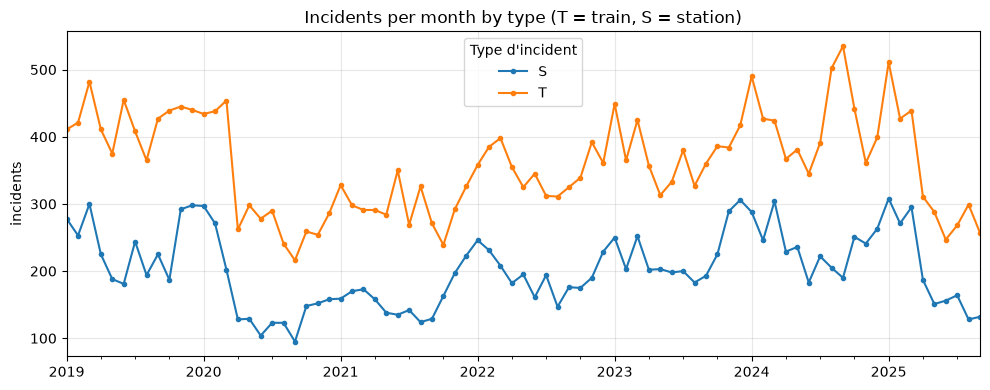

In [27]:
# Monthly incident counts by type, indexed by calendar month.
month = cal_date.dt.to_period("M")
monthly = raw.groupby([month, raw[type_col]]).size().unstack(fill_value=0)

print(f"Months covered: {monthly.index.min()} to {monthly.index.max()} "
      f"({len(monthly)} months)")

fig, ax = plt.subplots()
monthly.plot(ax=ax, marker=".")
ax.set_title("Incidents per month by type (T = train, S = station)")
ax.set_xlabel("")
ax.set_ylabel("incidents")
plt.tight_layout()
plt.show()

Keep in mind from the documentation: train incidents can be added **more than 30 days
after month end** (cause analysis takes time), so the latest months may be
under-counted. The data stops on 2025-09-30, so 2025 is a partial year.

## 12. First visual trends (train incidents only)

From here on we keep **train incidents** only, because station incidents never
interrupt service (section 10). Every count below is *raw*: it does not yet adjust
for how much service ran (planned km), which notebook 02 will handle.

In [28]:
train = raw[raw[type_col] == "T"].copy()
train["date"] = cal_date[train.index]
train["year"] = train["Année civile"].astype(int)
train["bucket"] = pd.Categorical(train["Incident en minutes"], categories=BUCKETS, ordered=True)

# Industry practice cited in the documentation: incidents under 5 minutes are not
# counted in reliability indicators. We use ">= 5 min" as a working definition of
# "service-affecting" for these plots only; the real target is decided later.
train["delay_5plus"] = train["bucket"] >= "05 à 09 min"
print(f"Train incidents: {len(train):,}  |  >= 5 min: {train['delay_5plus'].sum():,} "
      f"({100 * train['delay_5plus'].mean():.1f}%)")

Train incidents: 29,167  |  >= 5 min: 6,413 (22.0%)


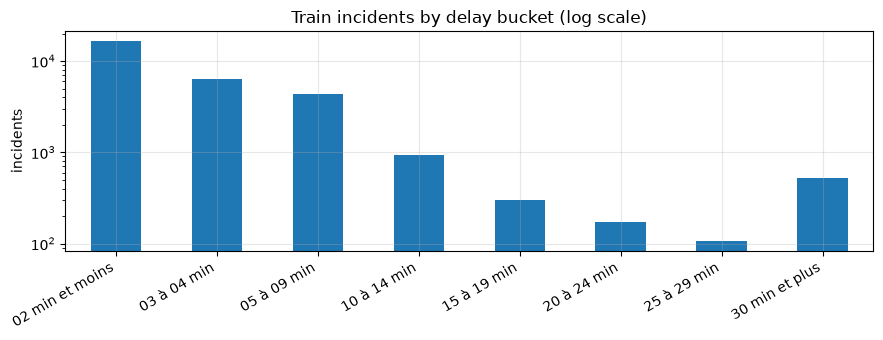

In [29]:
# Plot: how train incidents are spread across duration buckets.
fig, ax = plt.subplots(figsize=(9, 3.5))
train["bucket"].value_counts(sort=False).plot.bar(ax=ax, color="tab:blue")
ax.set_yscale("log")  # log scale: the shortest bucket dwarfs the rest
ax.set_title("Train incidents by delay bucket (log scale)")
ax.set_xlabel("")
ax.set_ylabel("incidents")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

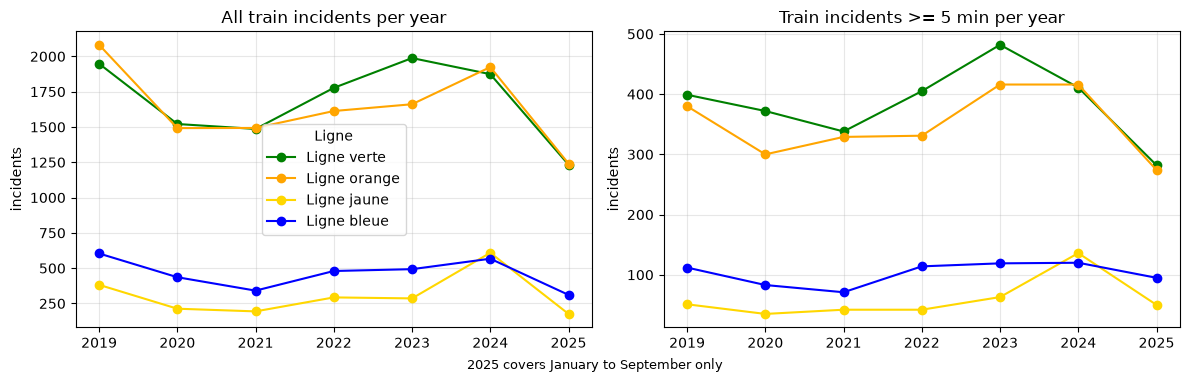

In [30]:
# Plot: yearly train incidents by line (the four main lines only).
MAIN_LINES = ["Ligne verte", "Ligne orange", "Ligne jaune", "Ligne bleue"]
LINE_COLORS = {"Ligne verte": "green", "Ligne orange": "orange",
               "Ligne jaune": "gold", "Ligne bleue": "blue"}

yearly = (train[train["Ligne"].isin(MAIN_LINES)]
          .groupby(["year", "Ligne"]).size().unstack()[MAIN_LINES])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
yearly.plot(ax=axes[0], marker="o", color=LINE_COLORS)
axes[0].set_title("All train incidents per year")
yearly_5 = (train[train["Ligne"].isin(MAIN_LINES) & train["delay_5plus"]]
            .groupby(["year", "Ligne"]).size().unstack()[MAIN_LINES])
yearly_5.plot(ax=axes[1], marker="o", color=LINE_COLORS, legend=False)
axes[1].set_title("Train incidents >= 5 min per year")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("incidents")
fig.suptitle("2025 covers January to September only", fontsize=9, y=0.02)
plt.tight_layout()
plt.show()

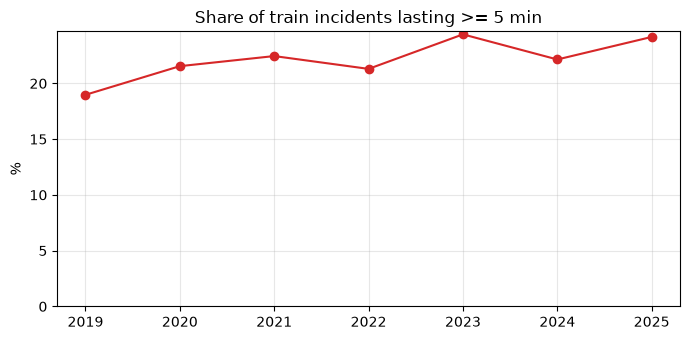

In [31]:
# Plot: share of train incidents lasting >= 5 min, by year.
# A share is unaffected by partial years, so 2025 is directly comparable here.
share_5 = 100 * train.groupby("year")["delay_5plus"].mean()

fig, ax = plt.subplots(figsize=(7, 3.5))
share_5.plot(ax=ax, marker="o", color="tab:red")
ax.set_ylim(0, None)
ax.set_title("Share of train incidents lasting >= 5 min")
ax.set_xlabel("")
ax.set_ylabel("%")
plt.tight_layout()
plt.show()

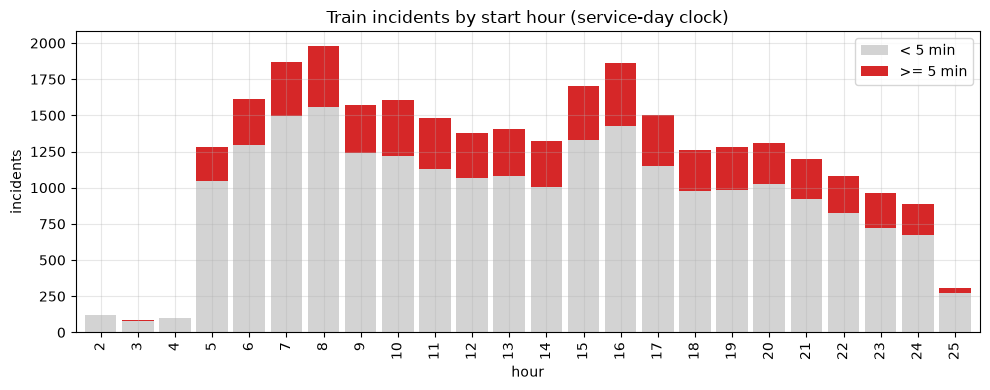

In [32]:
# Plot: hour of day when incidents start (service-day hours, so 24-26 = after midnight).
train["start_hour"] = train["Heure de l'incident"].str.slice(0, 2).astype(int)

fig, ax = plt.subplots()
by_hour = train.groupby(["start_hour", "delay_5plus"]).size().unstack(fill_value=0)
by_hour.columns = ["< 5 min", ">= 5 min"]
by_hour.plot.bar(ax=ax, stacked=True, color=["lightgray", "tab:red"], width=0.85)
ax.set_title("Train incidents by start hour (service-day clock)")
ax.set_xlabel("hour")
ax.set_ylabel("incidents")
plt.tight_layout()
plt.show()

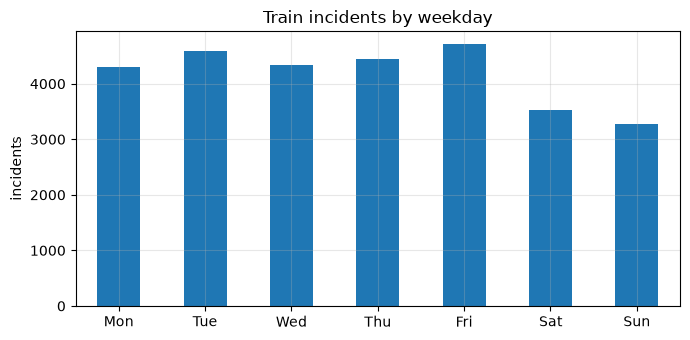

In [33]:
# Plot: weekday pattern, using the service-day weekday (1 = Monday, see section 6).
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday = train.groupby(train["Jour de la semaine"].astype(int)).size()
by_weekday.index = WEEKDAYS

fig, ax = plt.subplots(figsize=(7, 3.5))
by_weekday.plot.bar(ax=ax, color="tab:blue")
ax.set_title("Train incidents by weekday")
ax.set_xlabel("")
ax.set_ylabel("incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

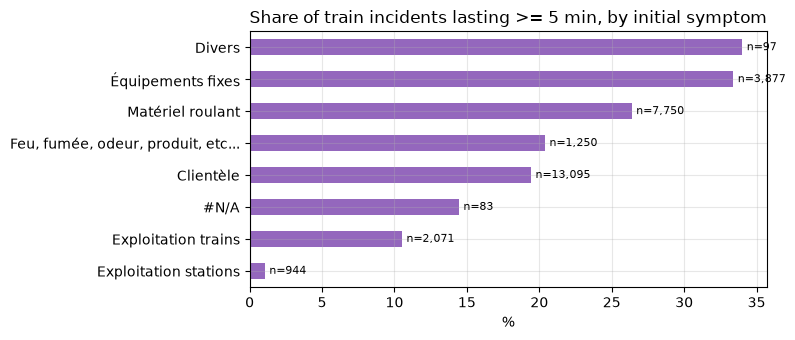

In [34]:
# Plot: does the risk of a long delay differ by the symptom recorded at report time?
# This is the most important candidate feature, since it is known immediately.
symptom = (train.groupby("Symptome")["delay_5plus"]
           .agg(rate="mean", n="size")
           .sort_values("rate"))

fig, ax = plt.subplots(figsize=(8, 3.5))
(100 * symptom["rate"]).plot.barh(ax=ax, color="tab:purple")
# Write the sample size at the end of each bar: small groups give noisy rates.
for i, (rate, n) in enumerate(zip(symptom["rate"], symptom["n"])):
    ax.annotate(f"n={n:,}", (100 * rate + 0.3, i), va="center", fontsize=8)
ax.set_title("Share of train incidents lasting >= 5 min, by initial symptom")
ax.set_xlabel("%")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

The symptom is recorded at report time and the long-delay rate varies a lot across
symptoms (from about 1% to over 30%), so it should be a strong early-warning feature.
Note that `Exploitation stations` and `Divers` are not in the documented symptom list.

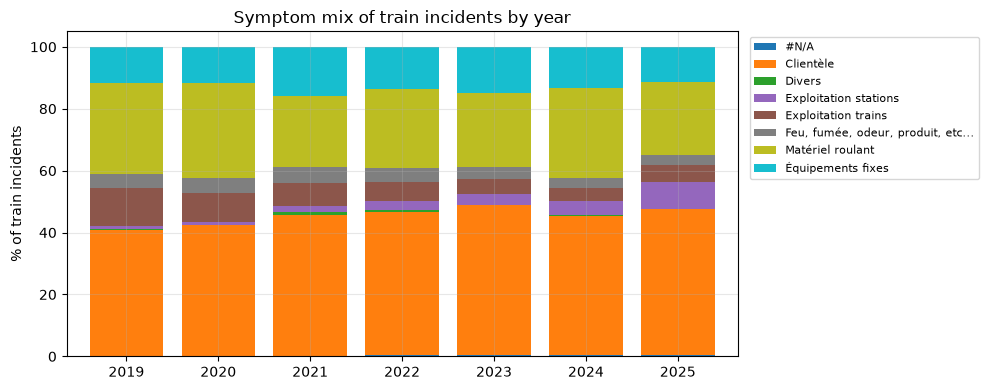

In [35]:
# Plot: is the classification itself drifting? Symptom mix by year.
# A shifting mix can mean real change *or* a change in how incidents get labelled.
mix = pd.crosstab(train["year"], train["Symptome"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(10, 4))
mix.plot.bar(ax=ax, stacked=True, width=0.8, colormap="tab10")
ax.set_title("Symptom mix of train incidents by year")
ax.set_xlabel("")
ax.set_ylabel("% of train incidents")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

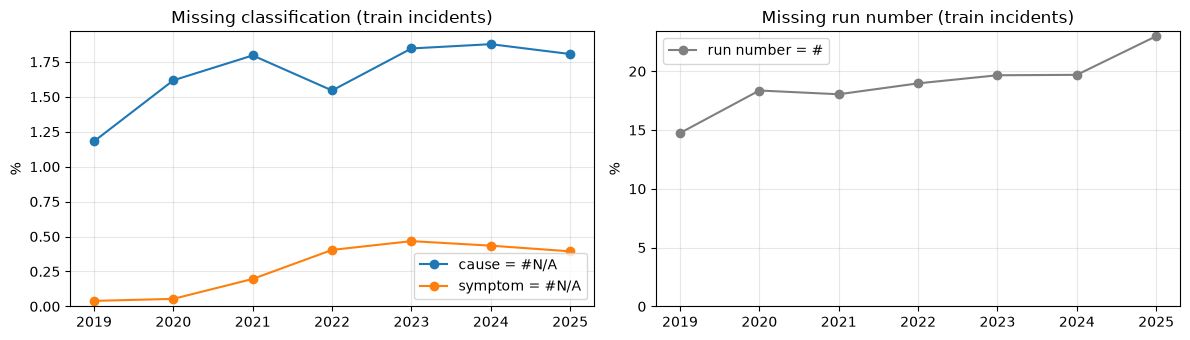

In [36]:
# Plot: data-quality drift. Share of train incidents with no cause or symptom recorded
# ("#N/A") and with no run number ("#"), by year.
quality = pd.DataFrame({
    "cause = #N/A":   train["Cause primaire"].eq("#N/A"),
    "symptom = #N/A": train["Symptome"].eq("#N/A"),
    "run number = #": train["Numéro de tournée"].eq("#"),
}).groupby(train["year"]).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
quality[["cause = #N/A", "symptom = #N/A"]].plot(ax=axes[0], marker="o")
axes[0].set_title("Missing classification (train incidents)")
quality[["run number = #"]].plot(ax=axes[1], marker="o", color="tab:gray")
axes[1].set_title("Missing run number (train incidents)")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("%")
    ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

## 13. Cleaning to-do list

Every item below comes from a cell above and becomes a decision in `code/cleaning/`.

| # | Column(s) | Issue | Proposed handling |
|---|---|---|---|
| 0 | all | 5 pairs of rows identical except for consecutive IDs | Keep (negligible); note as a probable double-entry pattern |
| 1 | all | Placeholders `#`, `#N/A`, `Non affecté` instead of nulls | Map to proper nulls; keep "structural" vs "unknown" distinct where it matters |
| 2 | `Type d'incident` | Station incidents always have 0-2 min delay and no causes | Exclude from the interruption target population; keep for descriptive counts |
| 3 | `Heure de l'incident`, `Heure de reprise` | Service-day clock (hours >= 24), two string formats; 60 rows use `02:00` instead of `26:00` | Parse to minutes; shift the `02:00` group by 24 h; build real start/end timestamps from service date + offset |
| 4 | date columns | Year / month / day / weekday (and the ID) describe the service day; `Jour calendaire` is the calendar date | Keep one service date + one real timestamp; drop the redundant columns |
| 5 | `Ligne` | Multi-line values in several orders; `Non affecté`; one `02-avr` artefact | Normalise to a sorted line set; flag multi-line; decide on the 2 bad categories |
| 6 | `Code de lieu` | Mixes stations, inter-station segments, facilities, whole lines; some name variants | Derive `location_kind` and a canonical station; map known aliases |
| 7 | `Cause primaire/secondaire`, `Symptome` | `#N/A` rows; post-hoc cause fields | Treat `#N/A` as unknown; never use causes as predictors (leakage) |
| 8 | `Type de matériel` | Fully determined by `Cause secondaire` | Drop (redundant, and inherits the cause leakage) |
| 9 | `Porte`, `Porte de voiture`, `Véhicule` | Door flag and door number disagree on ~2,500 rows; car IDs mostly `#` and high-cardinality | Combine into one "door involved" flag (either source); car ID only as a "recorded" flag, if at all |
| 10 | flags (`CAT`, `Urgence métro`, `Évacuation`, ...) | Timing unknown, probably response to severity | Exclude from the main model; consider in a sensitivity check |
| 11 | coverage | 2025 is partial; latest months may be under-reported | Use rates or shares, not raw yearly totals; treat recent months with care |